In [1]:
""" Importing required modules """
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns 
from mpl_toolkits.mplot3d import Axes3D
#np.random.seed(0)

In [2]:
""" Initialization of required parameters which have constant values """
N = 10000                                 # Population size
T = 500                                   # Time interval 
NN = np.arange(0, N)                      # Population size in array format (for plotting purposes)
TT = np.arange(0, T)                      # Time interval in array format (for plotting purposes)
SCE_50 = 20                               # A constant level of exposure that ensures subclinical exposure induced immunity with a probability 0.5. 
I_mf = 200                                # A constant increment in immunity whenever a person is cured of infection. (Units = EU)
P_r = 0.2                                 # Probability that an infected individual is cured  
I_sce = 20                                # A constant level of exposure that ensures subclinical exposure induced immunity with a probability 0.5. (Units = EU)
I_d = 2                                   # A small decrement by which immunity decreases every time unit if not exposed or infected. (Units = Eu)
I_c = 40                                  # Constant Immunity increase due to cross-immunity
a = 2                                     # Parameter deciding the sharpness of the sigmoid relationship 
r = 0.4                                   # Restriction parameter
ci = 0.005*r                               # Cross immunity parameter

In [3]:
# Creating empty 2D array of P values. This array would represent the modified probability of infection for each individual with respect to time.
Pone = np.zeros((N, T))
# Creating empty 2D array of P values. This array would represent the modified probability of infection for each individual with respect to time.
Ptwo = np.zeros((N, T))
# Creating empty 2D array of P_inf(i,t) values. This array would represent the probability of infection for each individual with respect to time.
P_inf = np.zeros((N, T))
# Creating zeros 2D array of P_sce(i,t) values. This array would represent the probability of sub-clinical exposure for each individual with respect to time.
P_sce = np.empty((N, T))
# Creating 2D array of ID_50(i,t) values and assigning values from the standard normal distribution. This array would represent the time evolution of the immunity of each of the individuals with respect to time.
ID_50 = np.zeros((N, 1))                              
# Creating array of E(i,0) values and assigning values from the normal distribution with mean = 70, sd = 30 (for t = 0 case). This array represents the expose bias of each of the individuals at initial time.
E = np.zeros((N, 1))
# Creating array of S(i,t) values. These are the infective states of the individuals with respect to time.
S = np.zeros((N, 1))
# Creating Array which will show the time evolution of I (Total infective state of the population)  
I = np.zeros((T,1))   

for j in range(N):
    x1 = np.random.choice(np.arange(0, 2), p=[0.95, 0.05])
    S[j, 0] = x1  
    x2 = round(np.random.normal(1, 8), 3)
    if (x2 < 0):
        x2 = 0.0001
        E[j, 0] = x2 * r
    else: 
        E[j, 0] = x2 * r
    x3 = round(np.random.normal(80, 10), 3)
    if (x3 < 0):
        x3 = 0.0001
        ID_50[j, 0] = x3
    else:
        ID_50[j, 0] = x3
    
print('Top to bottom - Individuals (0 to N) \nLeft to right - Time steps (0 to T) \nFirst column contains the values for T = 0 \n')
print("1. Initial State of the individuals in the population -- S(i,0):")
print(S)
print("\n 2. Initial expose bias of the individuals in the population -- E(i,0):")
print(E)
print("\n 3. Initial distribution of population immunity levels -- ID_50(i,0):")
print(ID_50)

Top to bottom - Individuals (0 to N) 
Left to right - Time steps (0 to T) 
First column contains the values for T = 0 

1. Initial State of the individuals in the population -- S(i,0):
[[0.]
 [0.]
 [0.]
 ...
 [0.]
 [0.]
 [0.]]

 2. Initial expose bias of the individuals in the population -- E(i,0):
[[1.844e-01]
 [4.000e-05]
 [4.000e-05]
 ...
 [9.932e-01]
 [1.910e+00]
 [4.000e-05]]

 3. Initial distribution of population immunity levels -- ID_50(i,0):
[[84.316]
 [79.206]
 [87.014]
 ...
 [73.03 ]
 [69.489]
 [68.076]]


In [4]:
X = np.zeros(T)
for t in range(T):
		P_inf_temp = np.zeros((N,))
		P_sce_temp = np.zeros((N,))
		P1_temp = np.zeros((N,))
		P2_temp = np.zeros((N,))
		S_temp = np.zeros((N, 1))
		ID_50_temp = np.zeros((N, 1))
		I_trans_temp = np.zeros((N, 1))
		I[t] = np.sum(S[:,-1])
		for n in range(N):
			I_trans_temp[n] = (30 * I[t] * r)/(250 + I[t])
			P_inf_temp[n] = (E[n][0])**a / ((ID_50[n][-1]**a) + (E[n][0]**a))
			P1_temp[n] = 1-((1-P_inf_temp[n])**(I_trans_temp[n]))
			P_sce_temp[n] = (E[n][0])**a / ((SCE_50)**a + (E[n][0])**a)
			P2_temp[n] = 1-((1-P_sce_temp[n])**(I_trans_temp[n]))
			# Condition to be imposed when S(t) = 1
			if S[n][-1] == 1:
				x4 = round(np.random.random(), 3)
				if x4 < P_r:
					S_temp[n] = 0
					ID_50_temp[n] = ID_50[n][-1] + I_mf
				else:
					S_temp[n] = 1
					x5 = round(np.random.random(), 3)
					if x5 < P1_temp[n]:
						S_temp[n] = 1
						ID_50_temp[n] = ID_50[n][-1]
					else:
						S_temp[n] = 0
						x6 = round(np.random.random(), 3)
						if x6 < P2_temp[n]:
							ID_50_temp[n] = ID_50[n][-1] + I_sce
						else:
							if (ID_50[n][-1] - I_d < 0):
								ID_50_temp[n] = 0
							else:
								ID_50_temp[n] = ID_50[n][-1] - I_d
			# Condition to be imposed when S(t) = 0
			else:
				x7 = round(np.random.random(), 3)
				if x7 < P1_temp[n]:
					S_temp[n] = 1
					ID_50_temp[n] = ID_50[n][-1]
				else:
					S_temp[n] = 0
					x8 = round(np.random.random(), 3)
					if x8 < P2_temp[n]:
						x9 = round(np.random.random(), 3)
						if x9 < ci:
							ID_50_temp[n] = ID_50[n][-1] + I_sce + I_c
						else:
							ID_50_temp[n] = ID_50[n][-1] + I_sce	
					else:
						x9 = round(np.random.random(), 3)
						if x9 < ci:
							if (ID_50[n][-1] - I_d - I_c < 0):
								ID_50_temp[n] = 0
							else:
								ID_50_temp[n] = ID_50[n][-1] - I_d + I_c
						else:
							if (ID_50[n][-1] - I_d < 0):
								ID_50_temp[n] = 0
							else:
								ID_50_temp[n] = ID_50[n][-1] - I_d
		ID_50 = np.hstack((ID_50, ID_50_temp))
		S = np.hstack((S, S_temp))
		P_inf[:,t] = P_inf_temp
		P_sce[:,t] = P_sce_temp
		Pone[:,t] = P1_temp
		Ptwo[:,t] = P2_temp
		x = np.mean(ID_50[:,t])
		X[t] = x
		#print('\n')
		#print("Infective state of the population:")
		#print(I[t])
		#print("Altered state of the population:")
		#print(S)
#np.savetxt('ID_50 (0.6, 50).csv', ID_50, delimiter=',', fmt='%s')
#np.savetxt('Infection state (0.6, 50).csv', I, delimiter=',', fmt='%s')
#np.savetxt('Mean ID_50 (0.6, 50).csv', X, delimiter=',', fmt='%s')
print("\nOverall trend:")
np.set_printoptions(suppress=True)
print(I.reshape(1,T))
print("\nMean Immunity levels:")
np.set_printoptions(suppress=True)
print(X)


Overall trend:
[[ 457.   77.   30.   18.   12.    4.    9.   12.   12.   15.   24.   28.
    32.   36.   45.   63.   95.  106.  132.  152.  162.  202.  238.  281.
   306.  321.  327.  348.  397.  423.  437.  467.  500.  565.  610.  679.
   711.  779.  882.  977. 1003. 1057. 1072. 1078. 1074. 1078. 1049.  984.
   884.  802.  726.  641.  565.  493.  450.  440.  409.  399.  379.  383.
   377.  378.  403.  393.  378.  354.  334.  323.  295.  285.  235.  225.
   204.  179.  177.  173.  157.  159.  151.  169.  161.  167.  176.  171.
   168.  165.  165.  152.  154.  142.  128.  119.  116.  108.   93.   88.
    89.   93.   85.   84.   87.   84.   83.   85.   84.   92.  103.   95.
    95.   87.   83.   84.   80.   70.   65.   64.   65.   66.   78.   81.
    77.   84.   89.   98.   90.   97.   90.  101.   95.  107.  104.  110.
   104.  108.   99.  103.  121.  128.  129.  137.  145.  170.  158.  170.
   190.  187.  196.  224.  221.  228.  225.  216.  230.  229.  223.  239.
   232.  216.  226.  2

In [5]:
print(P_inf.shape)
print(P_sce.shape)
print(S.shape)
print(ID_50.shape)
print(I.shape)

(10000, 500)
(10000, 500)
(10000, 501)
(10000, 501)
(500, 1)


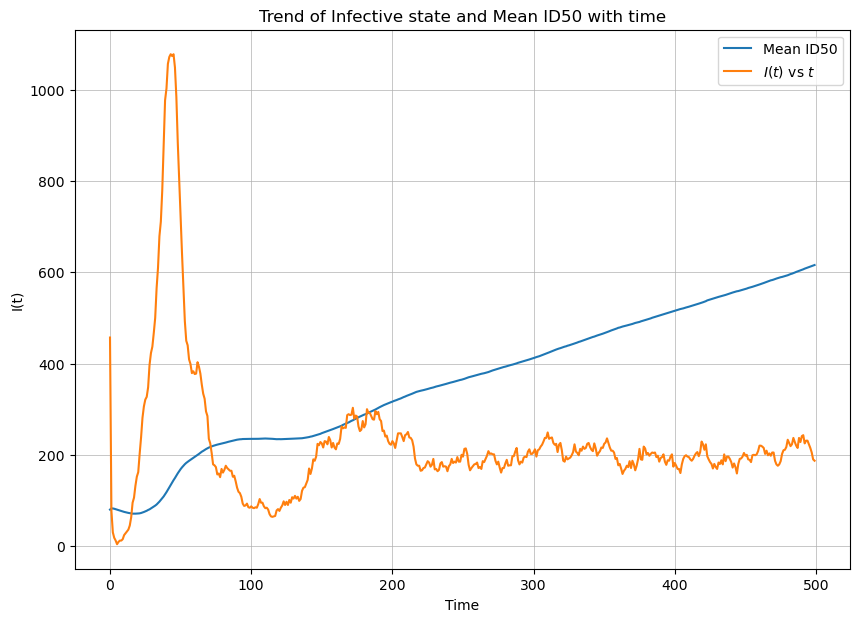

In [6]:
plt.figure(figsize=(10, 7))
X = np.zeros(T)
for t in range(T):
    x = np.mean(ID_50[:,t])
    X[t] = x
plt.plot(TT, X)
plt.plot(TT, I)
plt.title("Trend of Infective state and Mean ID50 with time")
plt.xlabel("Time")
plt.ylabel("I(t)")
plt.legend(["Mean ID50", "$I(t)$ vs $t$"])
plt.grid(linewidth=0.5)
plt.show()

<Figure size 1000x700 with 0 Axes>

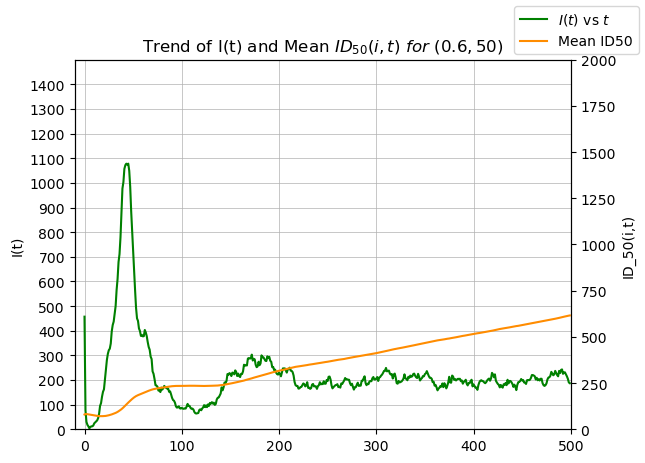

In [7]:
plt.figure(figsize=(10, 7))
X = np.zeros(T)
for t in range(T):
    x = np.mean(ID_50[:,t])
    X[t] = x
fig, ax2 = plt.subplots()
ax1 = ax2.twinx()
ax1.plot(TT, X, color = 'darkorange', label = 'Mean ID50')
ax2.plot(TT, I, color = 'green', label = '$I(t)$ vs $t$')
ax1.set_xlabel('Time')
ax1.set_ylabel('ID_50(i,t)')
ax2.set_ylabel('I(t)')
# Adjust axis limits based on estimates from abve graph
ax1.set(xlim =(-10, 500), ylim =(0, 2000), autoscale_on = False)   
ax2.set(xlim =(-10, 500), ylim =(0, 1500), autoscale_on = False)
ax2.set_yticks(range(0, 1500, 100))
ax2.grid(linestyle='-', linewidth=0.5)
fig.legend(loc='upper right')
ax1.title.set_text('Trend of I(t) and Mean $ID_{50}(i,t) \ for \ (0.6, 50)$')
plt.show()

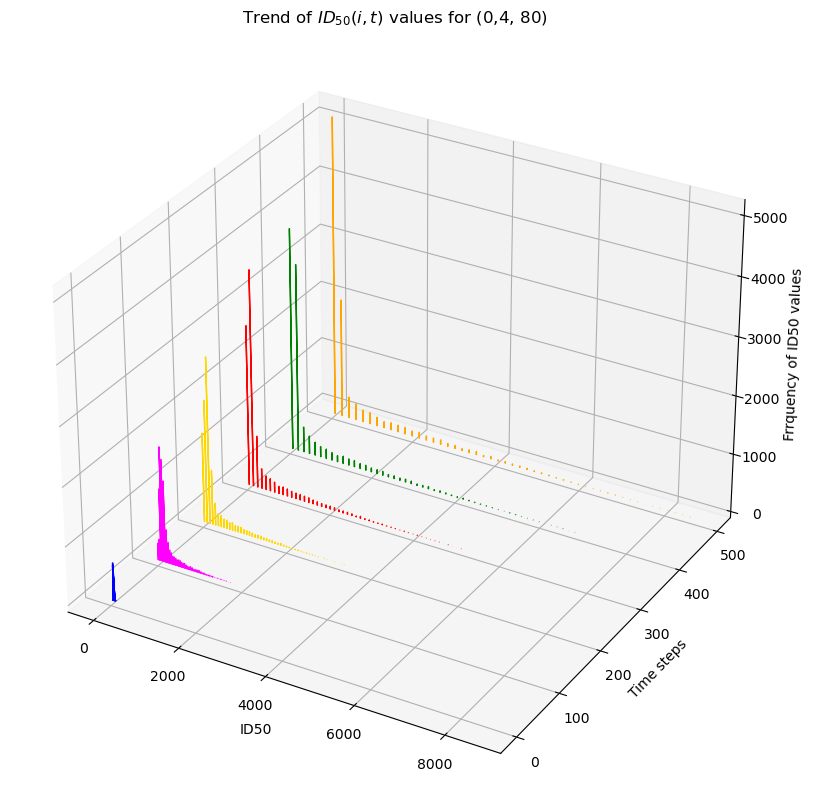

In [8]:
fig = plt.figure(figsize=(10, 10))
ax = fig.add_subplot(111, projection='3d')
nbins = 50
for c, a in zip(['orange','green', 'red', 'gold', 'magenta', 'blue'], [500, 400, 300, 200, 100, 0]):
    y = ID_50[:, a]
    hist, bins = np.histogram(y, bins=nbins)
    xs = (bins[:-1] + bins[1:])/2
    ax.bar(xs, hist, zs=a, zdir='y', color=c, ec=c, alpha=1.0)
ax.title.set_text('Trend of $ID_{50}(i,t)$ values for (0,4, 80)')
ax.set_zlabel('Frrquency of ID50 values')
ax.set_ylabel('Time steps')
ax.set_xlabel('ID50')
plt.show()


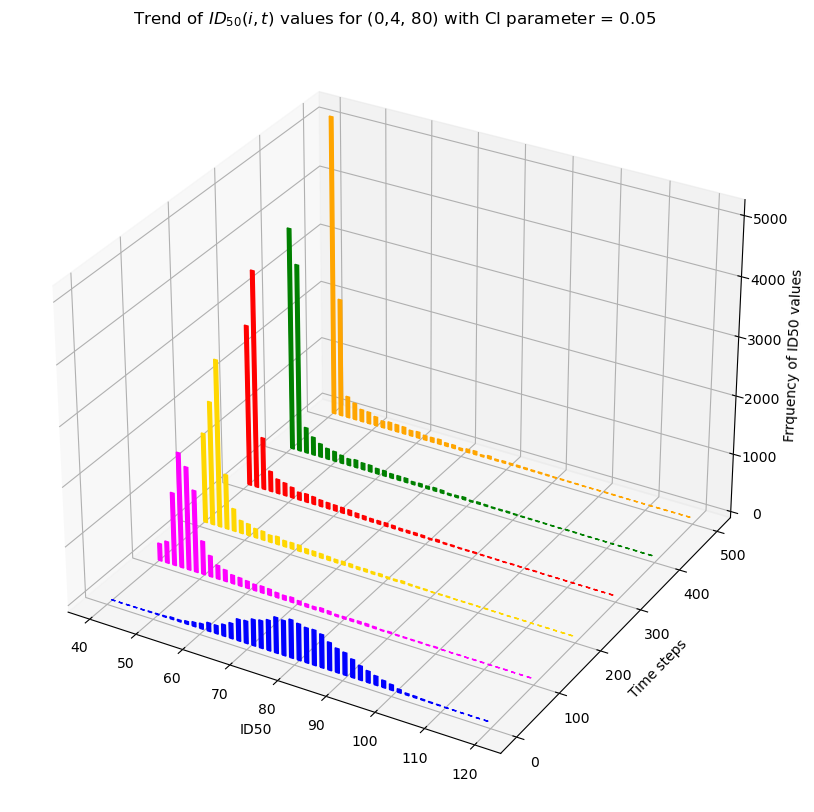

In [9]:
fig = plt.figure(figsize=(10, 10))
ax = fig.add_subplot(111, projection='3d')
nbins = 50
for c, a in zip(['orange','green', 'red', 'gold', 'magenta', 'blue'], [500, 400, 300, 200, 100, 0]):
    y = ID_50[:, a]
    hist, xbins = np.histogram(y, bins=nbins)
    xs = (bins[:-1] + bins[1:])/2
    ax.bar(xs, hist, zs=a, zdir='y', color=c, ec=c, alpha=1.0)
ax.title.set_text('Trend of $ID_{50}(i,t)$ values for (0,4, 80) with CI parameter = 0.005')
ax.set_zlabel('Frrquency of ID50 values')
ax.set_ylabel('Time steps')
ax.set_xlabel('ID50')
plt.show()


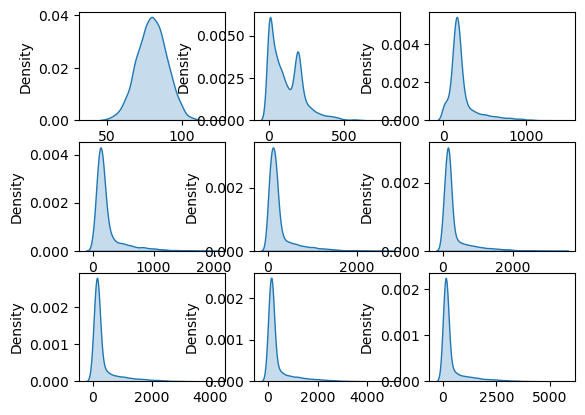

In [10]:
#fig = plt.figure(figsize=(15, 15))
fig = plt.figure()
ax = fig.add_subplot(3, 3, 1)
sns.kdeplot(ID_50[:, 0], fill=True, ax = ax)
ax = fig.add_subplot(3, 3, 2)
sns.kdeplot(ID_50[:, 40], fill=True, ax = ax)
ax = fig.add_subplot(3, 3, 3)
sns.kdeplot(ID_50[:, 80], fill=True, ax = ax)
ax = fig.add_subplot(3, 3, 4)
sns.kdeplot(ID_50[:, 120], fill=True, ax = ax)
ax = fig.add_subplot(3, 3, 5)
sns.kdeplot(ID_50[:, 160], fill=True, ax = ax)
ax = fig.add_subplot(3, 3, 6)
sns.kdeplot(ID_50[:, 200], fill=True, ax = ax)
ax = fig.add_subplot(3, 3, 7)
sns.kdeplot(ID_50[:, 240], fill=True, ax = ax)
ax = fig.add_subplot(3, 3, 8)
sns.kdeplot(ID_50[:, 280], fill=True, ax = ax)
ax = fig.add_subplot(3, 3, 9)
sns.kdeplot(ID_50[:, 320], fill=True, ax = ax)
plt.show()

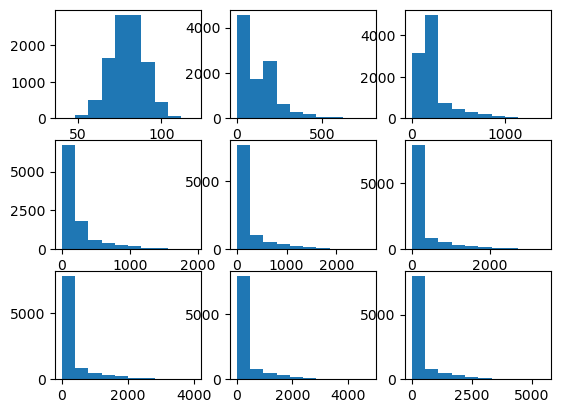

In [11]:
f, ax = plt.subplots(3, 3)
ax[0, 0].hist(ID_50[:, 0])
ax[0, 1].hist(ID_50[:, 40])
ax[0, 2].hist(ID_50[:, 80])
ax[1, 0].hist(ID_50[:, 120])
ax[1, 1].hist(ID_50[:, 160])
ax[1, 2].hist(ID_50[:, 200])
ax[2, 0].hist(ID_50[:, 240])
ax[2, 1].hist(ID_50[:, 280])
ax[2, 2].hist(ID_50[:, 320])
plt.show()

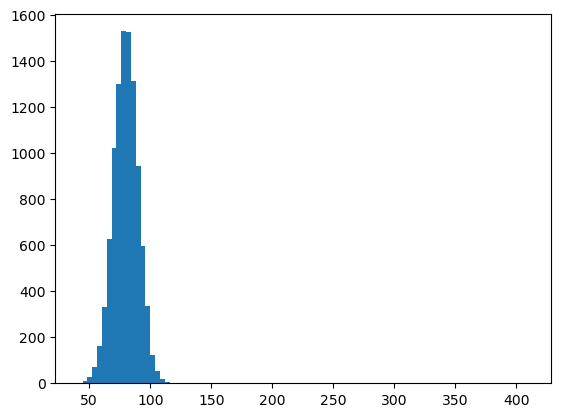

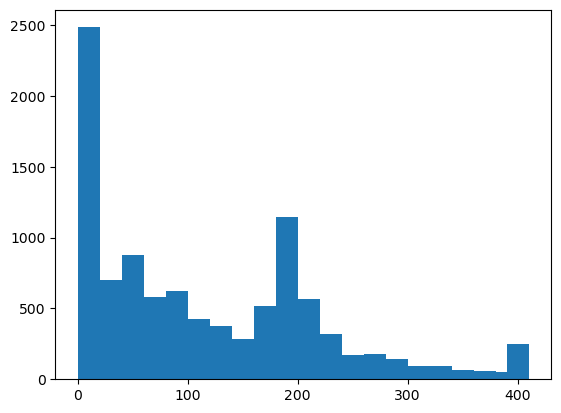

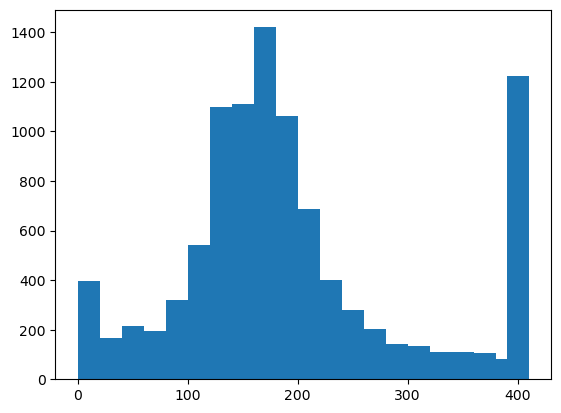

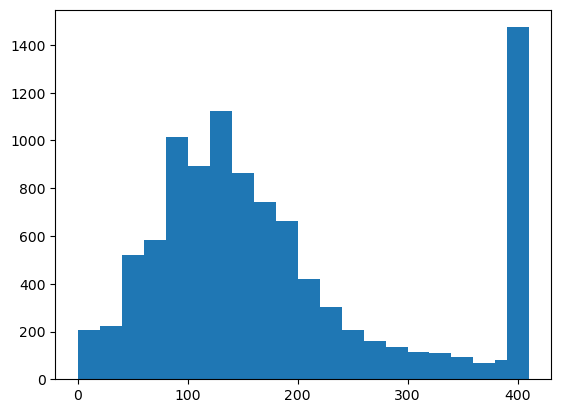

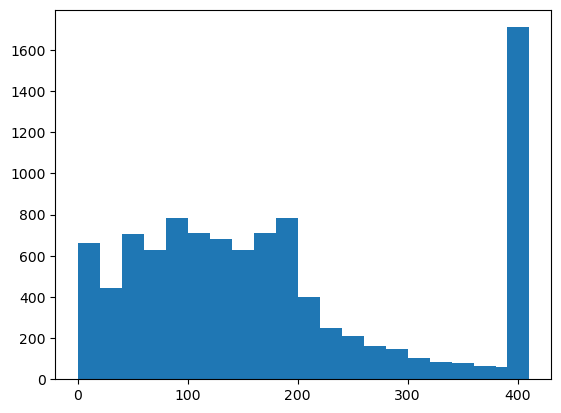

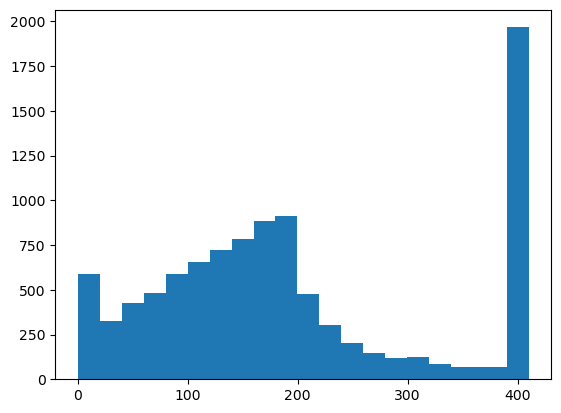

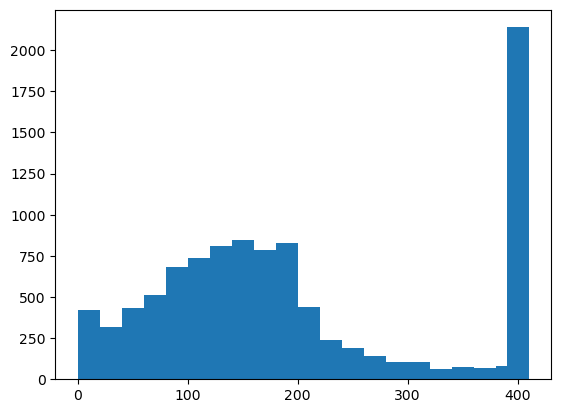

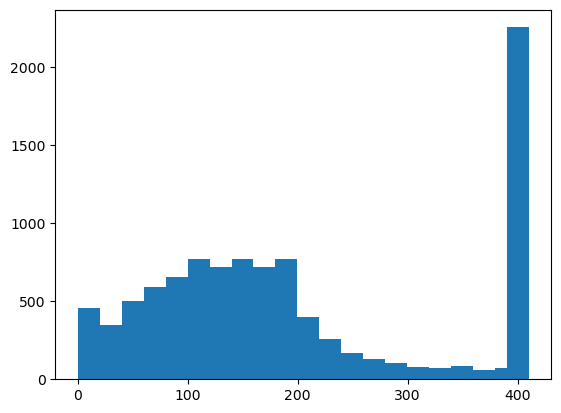

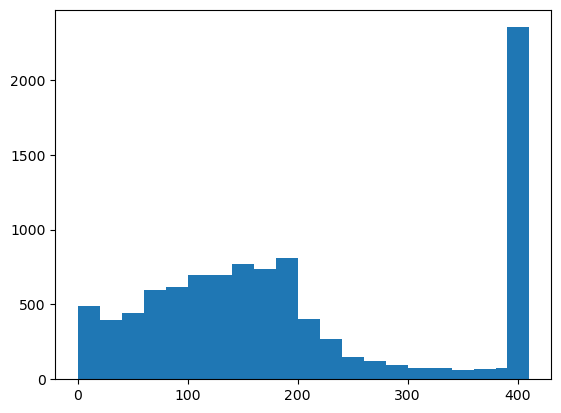

In [12]:
t = 0
n = 9           # Number of time steps for which histogram is to be plotted (t = 0 included)
#T = 320        # To be defined in accordance with the value at the beginning of the program
x = 40          # Increment of time steps. x = T/(n-1) is to be followed
bins = 20
for i in range(n):
    arr = ID_50[:, t]
    thresh = 400
    true_vals = arr > thresh
    true_sum = np.sum(true_vals)
    false_vals = np.array([i for i in arr if i < thresh])
    plt.hist(false_vals, bins=bins)
    plt.bar(400, true_sum, width=20)
    plt.show()
    t += x
